In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
df_kr = pd.read_csv("krim11.csv")
df_kra = pd.read_csv("krasnodar1 (1).csv")
df = pd.concat([df_kr, df_kra], ignore_index=True)
df.head()

,Регион,Город,Отель,Рейтинг,Автор,Отзыв,Дата
0,Республика Крым,Ялта,yaltaintourist_hotel,10.0,Elena,Отдыхала с дочкой в отеле Ялта-интурист с 12по...,21.05.2026
1,Республика Крым,Ялта,yaltaintourist_hotel,9.1,Mariya,"Приехали в Ялту на пару дней,я была по работе,...",29.11.2025
2,Республика Крым,Ялта,yaltaintourist_hotel,10.0,Marina,"Отель , как всегда, супер. Изменился в лучшую ...",19.06.2025
3,Республика Крым,Ялта,yaltaintourist_hotel,9.4,Elena,"Номер напоминает каюту лайнера, все продуманно...",31.10.2026
4,Республика Крым,Ялта,yaltaintourist_hotel,9.0,Vera,Комфортно в любое время год\r\nОт и до ж/д бес...,03.01.2026


In [ ]:
df.shape

(5015, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5015 entries, 0 to 5014
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Регион   5015 non-null   object 
 1   Город    5015 non-null   object 
 2   Отель    5015 non-null   object 
 3   Рейтинг  5015 non-null   float64
 4   Автор    5015 non-null   object 
 5   Отзыв    5015 non-null   object 
 6   Дата     5015 non-null   object 
dtypes: float64(1), object(6)
memory usage: 274.4+ KB


In [ ]:
df.isnull().sum()

,0
Регион,0
Город,0
Отель,0
Рейтинг,0
Автор,0
Отзыв,0
Дата,0


In [ ]:
df['Рейтинг'].value_counts().sort_index()

,count
Рейтинг,
1.0,8
1.2,1
1.3,1
1.4,1
1.5,1
...,...
9.6,303
9.7,346
9.8,196


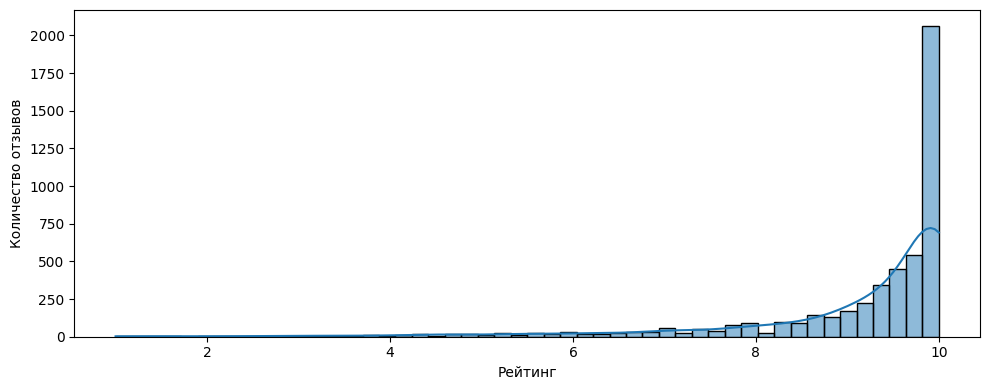

In [ ]:
plt.figure(figsize=(10, 4))
sns.histplot(df['Рейтинг'], bins=50, kde=True)
plt.xlabel('Рейтинг')
plt.ylabel('Количество отзывов')
plt.tight_layout()
plt.show()

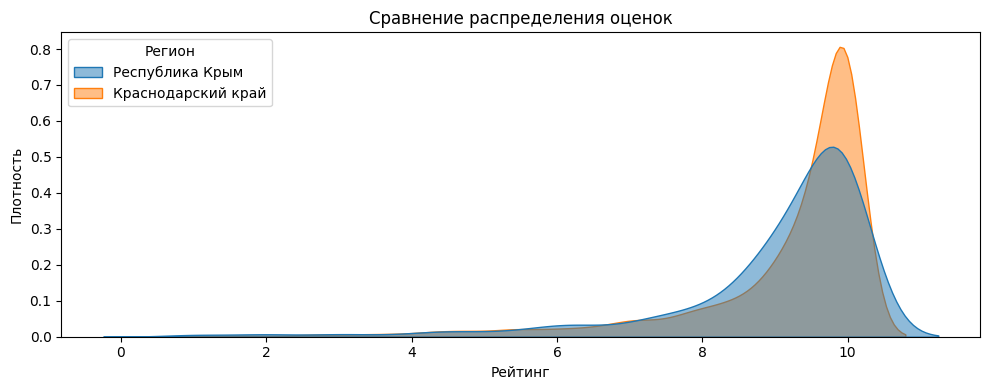

In [ ]:
plt.figure(figsize=(10, 4))
sns.kdeplot(data=df, x='Рейтинг', hue='Регион', fill=True, common_norm=False, alpha=0.5)
plt.xlabel('Рейтинг')
plt.ylabel('Плотность')
plt.title('Сравнение распределения оценок')
plt.tight_layout()
plt.show()

In [ ]:
def rating_to_4(x):
    if x < 4:    return 1
    elif x < 6:  return 2
    elif x < 8:  return 3
    else:        return 4

df['Рейтинг1'] = df['Рейтинг'].apply(rating_to_4)

In [ ]:
vc = df['Рейтинг1'].value_counts().sort_index()
stats = vc.to_frame('Количество').assign(Процент=(vc / vc.sum() * 100).round(2))
stats

,Количество,Процент
Рейтинг1,,
1,79,1.58
2,167,3.33
3,428,8.53
4,4341,86.56


In [ ]:
df['Дата'] = pd.to_datetime(df['Дата'], format='%d.%m.%Y', errors='coerce')
df['month'] = df['Дата'].dt.month

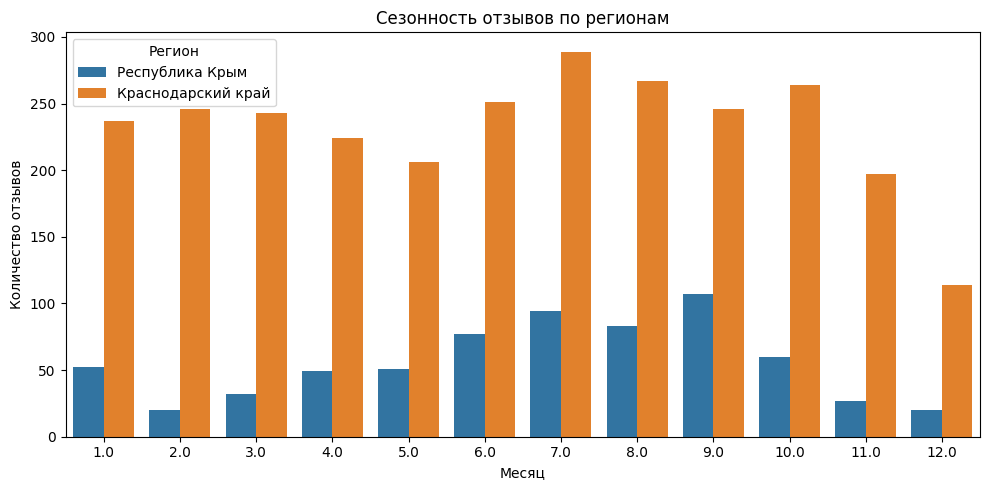

In [ ]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='month', hue='Регион')
plt.xlabel('Месяц')
plt.ylabel('Количество отзывов')
plt.title('Сезонность отзывов по регионам')
plt.tight_layout()
plt.show()

In [ ]:
df['year'] = df['Дата'].dt.year.astype('Int64')

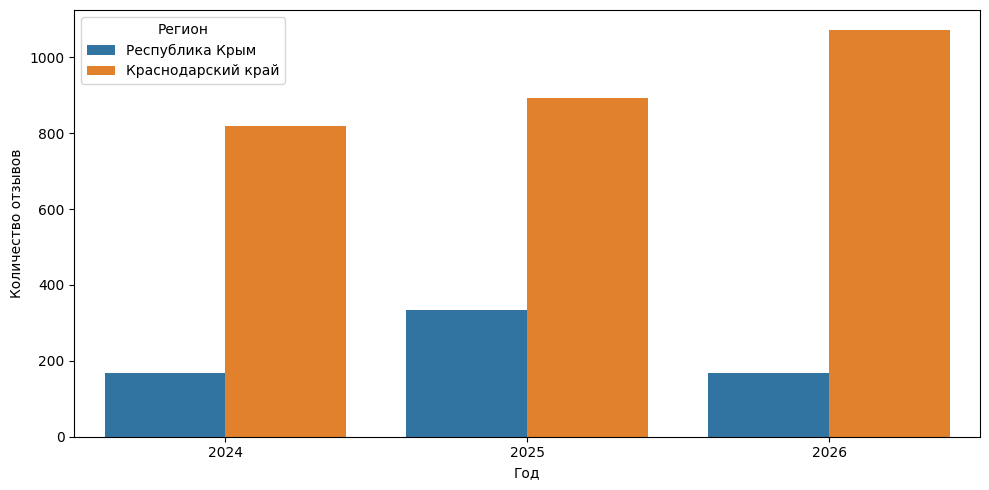

In [ ]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='year', hue='Регион')
plt.xlabel('Год')
plt.ylabel('Количество отзывов')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2174/998320140.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_cities.values, y=top_cities.index, palette='viridis')


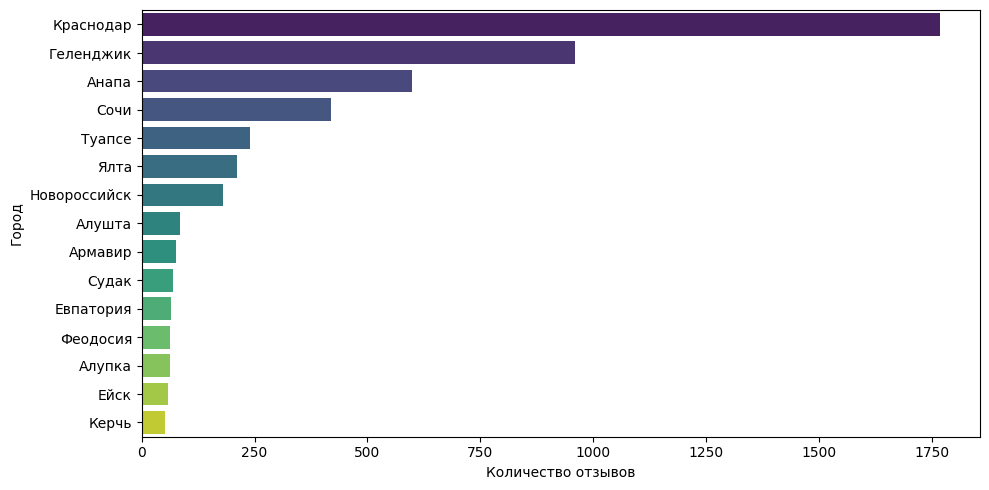

In [ ]:
plt.figure(figsize=(10, 5))
top_cities = df['Город'].value_counts().head(15)
sns.barplot(x=top_cities.values, y=top_cities.index, palette='viridis')
plt.xlabel('Количество отзывов')
plt.ylabel('Город')
plt.tight_layout()
plt.show()

 1 Очистка текста, лемматизация и удаление имен отелей

In [ ]:
!pip install pymorphy3 razdel nltk -q

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from razdel import tokenize
import pymorphy3

nltk.download('stopwords', quiet=True)
stop_ru = set(stopwords.words('russian'))
morph = pymorphy3.MorphAnalyzer()
geo_stopwords = set(df['Город'].astype(str).str.lower().unique())

for hotel in df['Отель'].astype(str).unique():
    clean_h = re.sub(r'[^а-яё]', '', hotel.lower())
    if len(clean_h) > 2:
        geo_stopwords.add(clean_h)

geo_stopwords.update(['ялта', 'интурист', 'сочи', 'анапа', 'геленджик', 'отель', 'гостиница', 'санаторий', 'пансионат'])

def clean_and_lemmatize(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'[^а-яё\s]', ' ', text)

    tokens = [t.text for t in tokenize(text)]
    lemmas = []
    for tok in tokens:
        if tok in stop_ru or len(tok) < 3:
            continue
        if tok in geo_stopwords:
            continue

        p = morph.parse(tok)[0]

        if any(tag in p.tag for tag in ['Name', 'Surn', 'Patr', 'Orgn']):
            continue

        if p.normal_form in geo_stopwords:
            continue

        lemmas.append(p.normal_form)

    return " ".join(lemmas)
df['Очищ_Отзыв'] = df['Отзыв'].apply(clean_and_lemmatize)

df[['Отзыв', 'Очищ_Отзыв']].head(10)

,Отзыв,Очищ_Отзыв
0,Отдыхала с дочкой в отеле Ялта-интурист с 12по...,отдыхать дочка май жить этаж заселить сразу пр...
1,"Приехали в Ялту на пару дней,я была по работе,...",приехать пара день работа решить совместить от...
2,"Отель , как всегда, супер. Изменился в лучшую ...",супер измениться хороший сторона приезжать это...
3,"Номер напоминает каюту лайнера, все продуманно...",номер напоминать каюта лайнер продуманно компа...
4,Комфортно в любое время год\r\nОт и до ж/д бес...,комфортно любой время год бесплатный трансфер ...
5,Понравилось почти всё: и расположение. и питан...,понравиться всё расположение питание обслужива...
6,"Здравствуйте, понравился отдых на все 100%! Ре...",здравствуйте понравиться отдых рекомендовать д...
7,Отдыхала в конце апреля 2026. Исключительное м...,отдыхать конец апрель исключительный место отд...
8,"Мне понравилась, цель моей поездки достигнута ...",понравиться цель мой поездка достигнуть отдохн...
9,"Один из лучших отелей в Ялте. Удобные, уютные ...",хороший удобный уютный номер везде кондиционер...


In [ ]:
df.tail()

,Регион,Город,Отель,Рейтинг,Автор,Отзыв,Дата,Рейтинг1,month,year,Очищ_Отзыв
5010,Краснодарский край,Краснодар,Отель Грейс Глобал,5.7,Nadezhda,Расположение и классная встреча охранник встре...,2026-09-01,2,9.0,2026,расположение классный встреча охранник встрети...
5011,Краснодарский край,Краснодар,Отель Грейс Глобал,7.6,Irina,В цену включен поход на пляж\n\nЦена-качество ...,2025-07-22,3,7.0,2025,цена включить поход пляж цена качество оставля...
5012,Краснодарский край,Краснодар,Отель Грейс Глобал,5.0,Vladimir,Сотрудники на ресепшн работают чётко и старают...,2024-09-29,2,9.0,2024,сотрудник ресепшн работать чётко стараться пом...
5013,Краснодарский край,Краснодар,Отель Грейс Глобал,6.6,Natalya,"Добрый день! Отель очень удобно расположен, вс...",2024-01-14,3,1.0,2024,добрый день очень удобно расположить доступнос...
5014,Краснодарский край,Краснодар,Отель Грейс Глобал,7.4,Dmitrij,Не очень качественная уборка номера. \r\nЗавт...,2024-01-30,3,1.0,2024,очень качественный уборка номер завтрак разноо...


2 Извлечение аспектов

In [ ]:
!pip install yake -q

In [ ]:
import yake

kw_extractor = yake.KeywordExtractor(
    lan="ru",
    n=2,
    dedupLim=0.7,
    top=10

def extract_aspects(text):
    if not text or len(text) < 5:
        return []
    keywords = kw_extractor.extract_keywords(text)
    return [kw for kw, score in keywords]

df['aspects'] = df['Очищ_Отзыв'].apply(extract_aspects)
df[['Очищ_Отзыв', 'aspects']].head(5)

,Очищ_Отзыв,aspects
0,отдыхать дочка май жить этаж заселить сразу пр...,"[отдыхать дочка, проживание однозначно, дочка ..."
1,приехать пара день работа решить совместить от...,"[приехать пара, работа решить, решить совмести..."
2,супер измениться хороший сторона приезжать это...,"[супер измениться, измениться хороший, хороший..."
3,номер напоминать каюта лайнер продуманно компа...,"[номер напоминать, данный момент, напоминать к..."
4,комфортно любой время год бесплатный трансфер ...,"[комфортно любой, вровень крыша, бесплатный тр..."
